# Court demand forecasting for a racquet club
**Question.** Can a club predict how many courts will be booked at each hour next week, so it can plan staffing and open play?

**Data.** Synthetic hourly booking counts for 26 weeks (6 AM to 9 PM) with a realistic shape: busy weekday evenings, busy weekend mornings, a slow dip in the middle of the period, and random noise. It is generated by `make_data.py`. Results show the method works; they are not facts about a real club.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv("data/court_bookings.csv", parse_dates=["date"])
df["dow"] = df.date.dt.dayofweek
df["week"] = (df.date - df.date.min()).dt.days // 7
df.head()

,date,hour,courts_booked,dow,week
0,2026-01-05,6,2,0,0
1,2026-01-05,7,10,0,0
2,2026-01-05,8,6,0,0
3,2026-01-05,9,4,0,0
4,2026-01-05,10,5,0,0


## 1. When is demand highest?

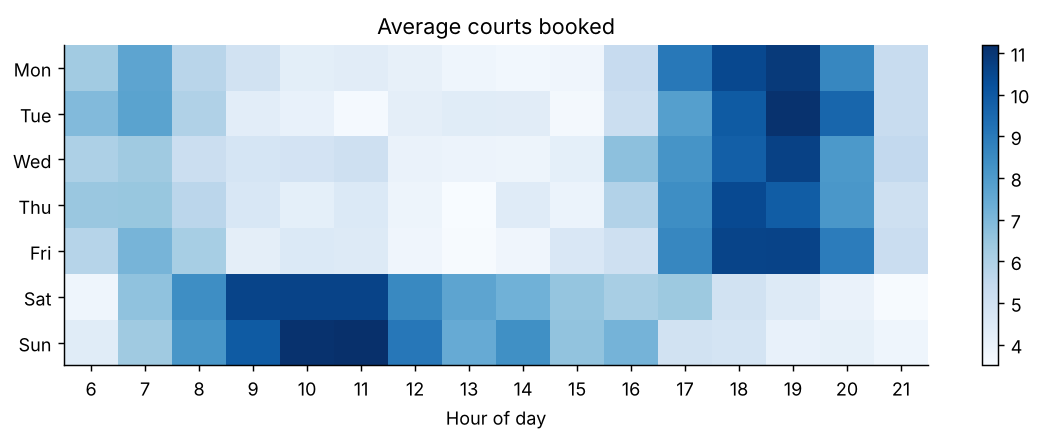

dow  hour
6    11      11.2
1    19      11.1
6    10      11.1
dtype: float64


In [2]:
heat = df.pivot_table(index="dow", columns="hour", values="courts_booked", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_xlabel("Hour of day"); ax.set_title("Average courts booked")
plt.colorbar(im); plt.tight_layout(); plt.savefig("figures/fig1_demand_heatmap.png"); plt.show()
peak = heat.stack().sort_values(ascending=False).head(3)
print(peak.round(1))

## 2. Forecast the last 4 weeks
I train on weeks 0 to 21 and test on weeks 22 to 25. Two baselines and one model:
* **Naive:** the overall average.
* **Seasonal naive:** the average for the same weekday and hour in training.
* **Ridge regression:** one effect for every weekday-and-hour slot, plus a weekly trend. My first attempt used separate weekday and hour effects and did worse than the seasonal naive baseline, because evening peaks differ between weekdays and weekends. Adding the combined slot fixed that.

In [3]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
train, test = df[df.week < 22].copy(), df[df.week >= 22].copy()
naive = np.full(len(test), train.courts_booked.mean())
seas = train.groupby(["dow", "hour"]).courts_booked.mean()
seasonal = test.set_index(["dow", "hour"]).index.map(seas).values

def feats(d):
    X = pd.get_dummies((d.dow.astype(str) + "_" + d.hour.astype(str)).rename("slot"), dtype=float)  # weekday x hour
    X["week"] = d.week.values
    return X
Xtr, Xte = feats(train), feats(test).reindex(columns=feats(train).columns, fill_value=0)
model = Ridge(alpha=1.0).fit(Xtr, train.courts_booked)
lin = model.predict(Xte)
res = pd.Series({
    "Naive average": mean_absolute_error(test.courts_booked, naive),
    "Seasonal naive": mean_absolute_error(test.courts_booked, seasonal),
    "Ridge (weekday x hour + trend)": mean_absolute_error(test.courts_booked, lin),
}).round(2)
res.name = "MAE (courts)"
res

Naive average                     2.66
Seasonal naive                    1.88
Ridge (weekday x hour + trend)    1.82
Name: MAE (courts), dtype: float64

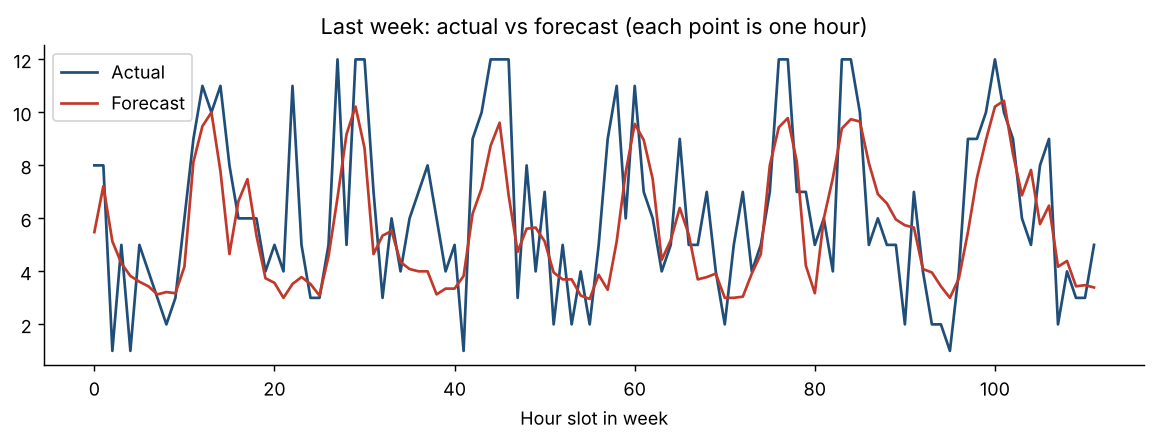

In [4]:
test["pred"] = lin
wk = test[test.week == 25]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(range(len(wk)), wk.courts_booked.values, label="Actual", color="#1f4e79")
ax.plot(range(len(wk)), wk.pred.values, label="Forecast", color="#c0392b")
ax.set_title("Last week: actual vs forecast (each point is one hour)"); ax.set_xlabel("Hour slot in week"); ax.legend()
plt.tight_layout(); plt.savefig("figures/fig2_forecast_last_week.png"); plt.show()

## 3. What the club can do with this
* Staff the front desk for the top-demand slots listed above.
* Offer discounted off-peak bookings in the lowest-demand slots.
* Re-run weekly; error is about the size shown in the table, so treat forecasts as planning guides, not guarantees.

**Limits.** Synthetic data, one location, no holidays or weather, and only 26 weeks.